# 01 - Dataset Exploration (EDA) | VNDCash
**Dự án**: XÂY DỰNG ỨNG DỤNG NHẬN DIỆN TIỀN GIẤY VIỆT NAM BẰNG CNN  
**Thành viên phụ trách**: Thành viên A (Data Engineering & Data Pipeline)  
**Bộ dữ liệu nguồn**: KaggleHub `nguyentrongdai/vietnamese-currency`  

Notebook này thực hiện khám phá, phân tích thống kê và trực quan hóa toàn diện bộ dữ liệu VNDCash.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Đảm bảo sys.path trỏ đúng PROJECT_ROOT
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Project Root:', PROJECT_ROOT)

Project Root: c:\Users\ndt06\Desktop\VNDCash


## 1. Nạp và kiểm tra bảng Metadata chuẩn hóa

In [2]:
metadata_path = PROJECT_ROOT / 'data' / 'metadata' / 'metadata.csv'
df = pd.read_csv(metadata_path)
print(f'Tổng số mẫu dữ liệu: {len(df)}')
print(f'Tổng số tờ tiền (note_id) độc lập: {df["note_id"].nunique()}')
df.head()

Tổng số mẫu dữ liệu: 1962
Tổng số tờ tiền (note_id) độc lập: 198


,image_id,filename,rel_path,denomination,label_idx,material,note_id,width,height,channels,color_mode,aspect_ratio,file_size_bytes,md5_hash,is_valid
0,1000_0000,001000_0.png,data/raw/001000/001000_0.png,1000,0,cotton,NOTE_1000_000,192,144,3,RGB,1.333,52550,9b61b958bf3295f37f543b867e28987b,True
1,1000_0001,001000_1.png,data/raw/001000/001000_1.png,1000,0,cotton,NOTE_1000_000,192,144,3,RGB,1.333,54667,a19f9c409bff21f8a864eed43ea620f8,True
2,1000_0002,001000_2.png,data/raw/001000/001000_2.png,1000,0,cotton,NOTE_1000_000,192,144,3,RGB,1.333,54361,992b466509b35ccaa783b0de68ed843b,True
3,1000_0003,001000_3.png,data/raw/001000/001000_3.png,1000,0,cotton,NOTE_1000_000,192,144,3,RGB,1.333,48231,4bfb710de8b025a7bc7aada78881d8ac,True
4,1000_0004,001000_4.png,data/raw/001000/001000_4.png,1000,0,cotton,NOTE_1000_000,192,144,3,RGB,1.333,47917,46bb0715ea2edd488444d9c3583d5762,True


## 2. Thống kê phân bố số lượng ảnh theo 09 mệnh giá
Ghi nhận rõ những lớp thiếu mẫu theo tiêu chuẩn nghiệm thu của Thành viên A.

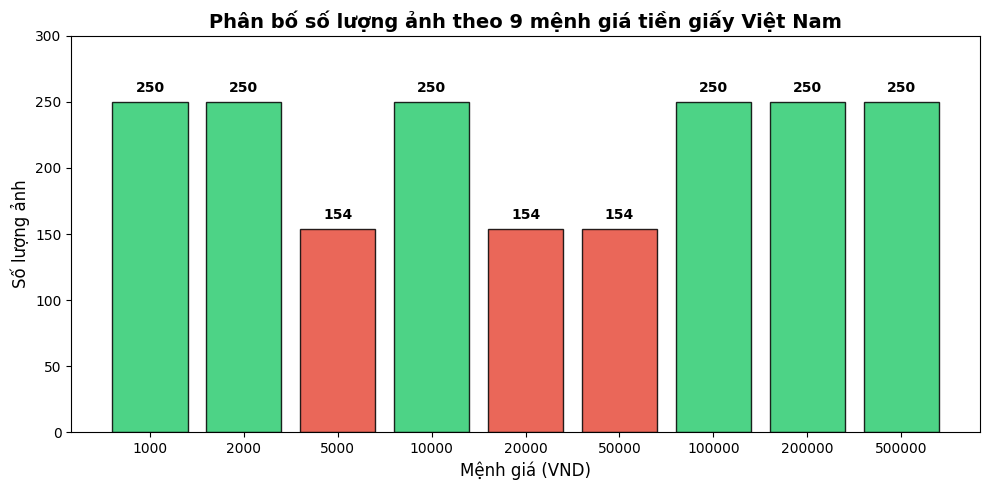

Lưu ý: Mệnh giá 5.000, 20.000 và 50.000 có 154 ảnh (thiếu 38.4% so với các lớp 250 ảnh).


In [3]:
denom_order = ['1000', '2000', '5000', '10000', '20000', '50000', '100000', '200000', '500000']
counts = df['denomination'].astype(str).value_counts().reindex(denom_order)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if c == 250 else '#e74c3c' for c in counts.values]
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f'{int(yval)}', ha='center', va='bottom', fontweight='bold')

ax.set_title('Phân bố số lượng ảnh theo 9 mệnh giá tiền giấy Việt Nam', fontsize=14, fontweight='bold')
ax.set_xlabel('Mệnh giá (VND)', fontsize=12)
ax.set_ylabel('Số lượng ảnh', fontsize=12)
ax.set_ylim(0, 300)
plt.tight_layout()
plt.show()
print('Lưu ý: Mệnh giá 5.000, 20.000 và 50.000 có 154 ảnh (thiếu 38.4% so với các lớp 250 ảnh).')

## 3. Thống kê chất liệu tờ tiền: Cotton vs Polymer

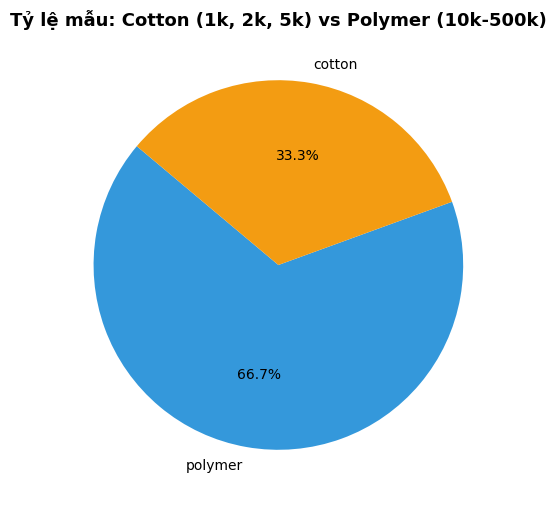

In [4]:
material_counts = df['material'].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(material_counts, labels=material_counts.index, autopct='%1.1f%%', startangle=140, colors=['#3498db', '#f39c12'])
ax.set_title('Tỷ lệ mẫu: Cotton (1k, 2k, 5k) vs Polymer (10k-500k)', fontsize=13, fontweight='bold')
plt.show()

## 4. Trực quan hóa mẫu ảnh của từng mệnh giá (9 Lớp)

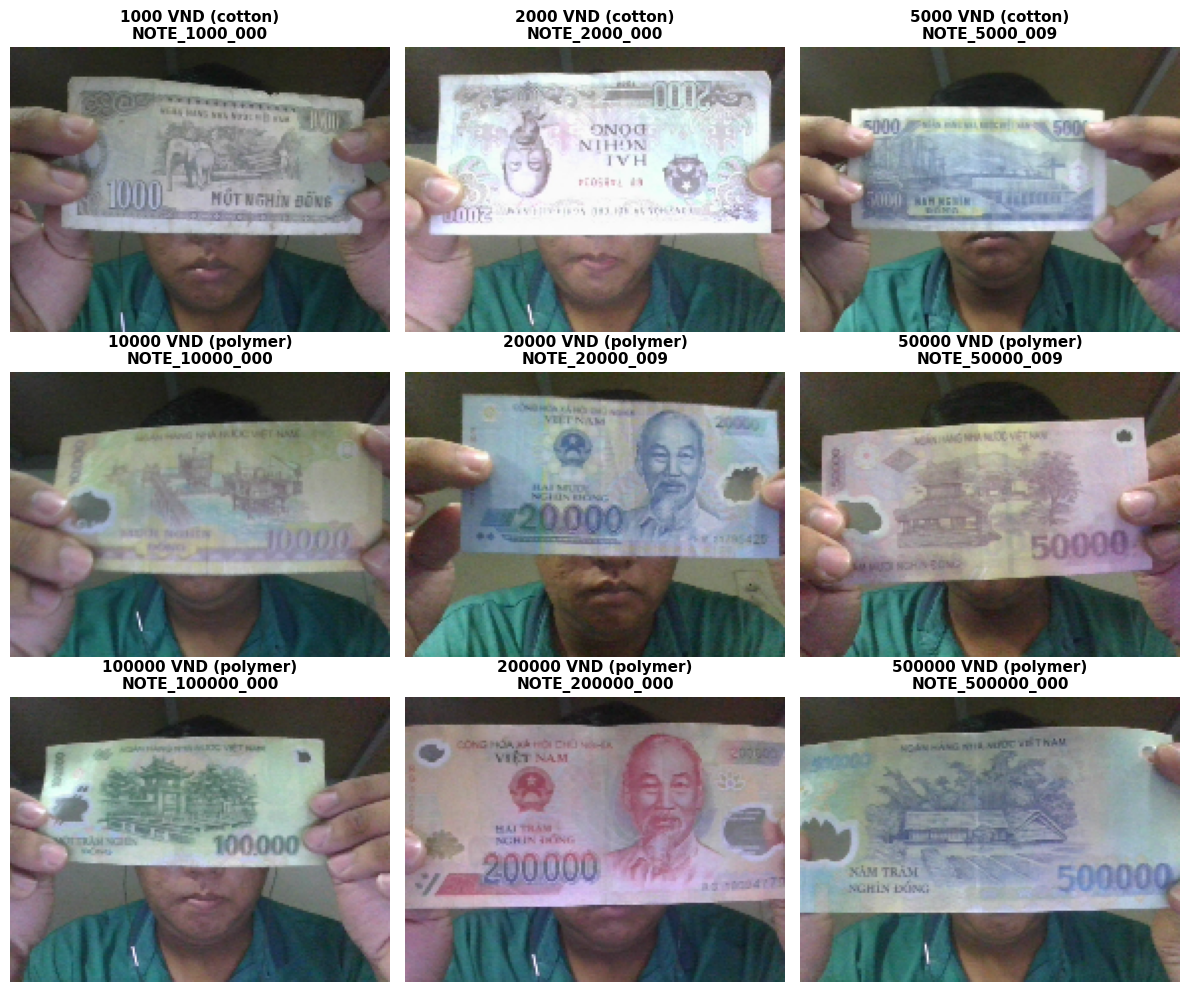

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for i, denom in enumerate(denom_order):
    ax = axes[i // 3, i % 3]
    sample = df[df['denomination'] == int(denom)].iloc[0]
    img_path = PROJECT_ROOT / sample['rel_path']
    im = Image.open(img_path)
    ax.imshow(im)
    ax.set_title(f"{denom} VND ({sample['material']})\n{sample['note_id']}", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Phân tích Split và Kiểm tra Chống Rò Rỉ Dữ Liệu (Data Leakage Verification)

In [6]:
splits_path = PROJECT_ROOT / 'data' / 'metadata' / 'splits.csv'
df_splits = pd.read_csv(splits_path)

summary = df_splits.groupby('split').agg(
    so_anh=('image_id', 'count'),
    so_to_tien=('note_id', 'nunique')
).loc[['train', 'val', 'test']]
summary['ty_le_%'] = (summary['so_anh'] / len(df_splits) * 100).round(2)
print(summary)

# Xác thực giao diện chống rò rỉ
train_notes = set(df_splits[df_splits['split'] == 'train']['note_id'])
val_notes = set(df_splits[df_splits['split'] == 'val']['note_id'])
test_notes = set(df_splits[df_splits['split'] == 'test']['note_id'])

print('\nKiểm tra trùng lặp note_id giữa các tập:')
print('Train vs Val :', len(train_notes & val_notes))
print('Train vs Test:', len(train_notes & test_notes))
print('Val vs Test  :', len(val_notes & test_notes))
assert len(train_notes & val_notes) == 0 and len(train_notes & test_notes) == 0 and len(val_notes & test_notes) == 0
print('[PASSED] Toàn bộ note_id độc lập tuyệt đối giữa các tập!')

       so_anh  so_to_tien  ty_le_%
split                             
train    1362         138    69.42
val       300          30    15.29
test      300          30    15.29

Kiểm tra trùng lặp note_id giữa các tập:
Train vs Val : 0
Train vs Test: 0
Val vs Test  : 0
[PASSED] Toàn bộ note_id độc lập tuyệt đối giữa các tập!
